# 01 · Preprocessing — Cohen 2021 Multiple Myeloma (malignant compartment)

Isolate malignant plasma cells, threshold thin samples by a **data-driven multiplicative
gap** (restricted to a sensible floor so the long low-count tail cannot swallow the cut),
integrate patients (Harmony), embed, and remove any detached islands. Multiple-myeloma
plasma cells are strongly **patient-clonal**, so batch integration is the crux of Gate 1:
we select the integration strength on the regenerated embedding across a `theta` sweep with
a per-neighbourhood metric (iLISI), never on a single scalar.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Cohen2021_Hematologic-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# dataset folder on disk is the run name minus the '-1' re-run suffix
data_name = name[:-2] if name.endswith('-1') else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + data_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Cohen2021_Hematologic-1 | category: Hematologic


### Load malignant compartment
The loader auto-detects normalization from the matrix filename (`Exp_data_UMIcounts.mtx` →
counts, so `normalize_total` + `log1p`) and defaults `celltype` to `Malignant`. Cohen 2021
annotates every cell as malignant plasma cell, so the malignant mask keeps the whole atlas.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())
print('cell-cycle phase (shallow MARS-seq -> mostly NaN/Not cycling):',
      adata.obs['cell_cycle_phase'].value_counts(dropna=False).to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Cohen2021_Hematologic
Done.
full atlas: (39157, 57874)
malignant: (33599, 57874) | samples: 73 | patients: 43
expression: X max 6.99 (log1p of normalize_total counts)
cell-cycle phase (shallow MARS-seq -> mostly NaN/Not cycling): {nan: 23121, 'Not cycling': 9491, 'G2/M': 497, 'G1/S': 350, 'Intermediate': 140}


### Sample thresholding — derived by a floor-restricted multiplicative gap
Per-sample malignant counts span two orders of magnitude and fall off **smoothly** — there is
no clean count gap (the calibration audit's C3 premise fails here). The raw largest
multiplicative ratio sits in the 2→1 tail, which is meaningless. We therefore find the largest
multiplicative cliff **among samples with ≥20 cells** (a minimal floor below which a sample
cannot inform a manifold), and cut at the geometric mean across it. This keeps the bulk of the
data while dropping only genuinely thin samples.

In [4]:
n = adata.obs['sample'].value_counts()
vals = np.sort(n.values)[::-1].astype(float)
floor = 20
sub = vals[vals >= floor]
ratios = sub[:-1] / sub[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(sub[gap] * sub[gap+1]))
print('per-sample counts (sorted):', vals.astype(int).tolist())
print(f'largest gap among samples>={floor} cells: {int(sub[gap])} -> {int(sub[gap+1])} '
      f'(ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells; '
      f'patients: {adata.obs["patient"].nunique()}')

per-sample counts (sorted): [1476, 1450, 1145, 1042, 1040, 1019, 970, 967, 953, 941, 938, 926, 900, 885, 873, 796, 792, 741, 735, 666, 665, 657, 606, 603, 599, 599, 592, 578, 572, 525, 516, 503, 500, 486, 466, 463, 449, 449, 414, 407, 384, 364, 347, 322, 308, 211, 208, 204, 200, 158, 144, 143, 133, 117, 77, 74, 59, 50, 42, 40, 29, 26, 14, 9, 8, 6, 5, 3, 3, 2, 2, 2, 1]
largest gap among samples>=20 cells: 117 -> 77 (ratio 1.52)
derived threshold (geometric mean across the gap) = 94
kept 54/73 samples -> 33147 cells; patients: 41


### Overdispersion → PCA → Harmony integration strength sweep
`n_pcs` is read off the scree (variance ratio flattens below ~0.005), not inherited. `theta`
is selected by a per-neighbourhood **iLISI** sweep (effective number of samples in each cell's
90-NN neighbourhood; higher = better mixing, ceiling = number of samples): we take the theta
past which mixing saturates without collapsing biology.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
n_pcs = int(np.argmax(vr < 0.005))
print('scree: variance ratio drops below 0.005 at PC', n_pcs, '-> n_pcs =', n_pcs)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 482 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 482
scree: variance ratio drops below 0.005 at PC 21 -> n_pcs = 21


In [6]:
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1/np.sum(p**2)
    return out
samp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:, :n_pcs], samp))
sweep = {}
for th in [1, 2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = np.median(ilisi(adata.obsm['X_pca_harmony'][:, :n_pcs], samp))
print(f'iLISI median (of {nsamp} samples) | pre-Harmony {il_pre:.2f} | sweep',
      {k: round(v,2) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing saturates; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

2026-08-05 17:51:29,287 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:51:32,500 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:51:32,747 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 17:51:46,418 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 17:52:00,164 - harmonypy - INFO - Iteration 3 of 30
2026-08-05 17:52:15,195 - harmonypy - INFO - Iteration 4 of 30
2026-08-05 17:52:29,691 - harmonypy - INFO - Iteration 5 of 30
2026-08-05 17:52:39,465 - harmonypy - INFO - Iteration 6 of 30
2026-08-05 17:52:47,862 - harmonypy - INFO - Converged after 6 iterations
2026-08-05 17:52:50,285 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 17:52:53,209 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 17:52:53,447 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 17:53:06,770 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 17:53:20,993 - harmonypy - INFO - Iteration 3 of 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and keep the
largest connected component — stripping physically detached specks while leaving the
continuous mass intact.

In [7]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape[0], 'cells,', adata.obs['sample'].nunique(), 'samples')

removed 80 cells in 3 detached islands
after island removal: 33067 cells, 54 samples


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw joint embedding. A single **rigid rotation** of
the axis of maximal variance to horizontal (distances preserved) gives a layout every
downstream panel re-uses, with the Gast/pSom-high developmental origin placed on the **left**.

In [8]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
ang = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-ang), -np.sin(-ang)], [np.sin(-ang), np.cos(-ang)]])
adata.obsm['X_umap_lin'] = c @ Rm.T
print(f'manifold aspect (max/min std): {aspect:.2f}  (near 1 -> round diffuse cloud, not a Y or strip)')
print(f'house orientation: rigid rotation {np.degrees(ang):+.1f}deg stored as X_umap_lin')

manifold aspect (max/min std): 1.00  (near 1 -> round diffuse cloud, not a Y or strip)
house orientation: rigid rotation -46.8deg stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity (judged on the embedding)
The panels below show the regenerated embedding coloured by `sample`, `patient`, and cell-cycle.
At low integration the manifold breaks into patient-dominated density lobes (batch, not biology);
by theta=10 the samples and patients speckle-intermix throughout one connected mass. The
per-neighbourhood iLISI sweep above quantifies that saturation. Island removal leaves a single
connected component. **Gate 1 = GO.**

Gate 1: samples/patients intermix per-neighbourhood (iLISI 14.2 of 54) on one continuous connected manifold -> GO


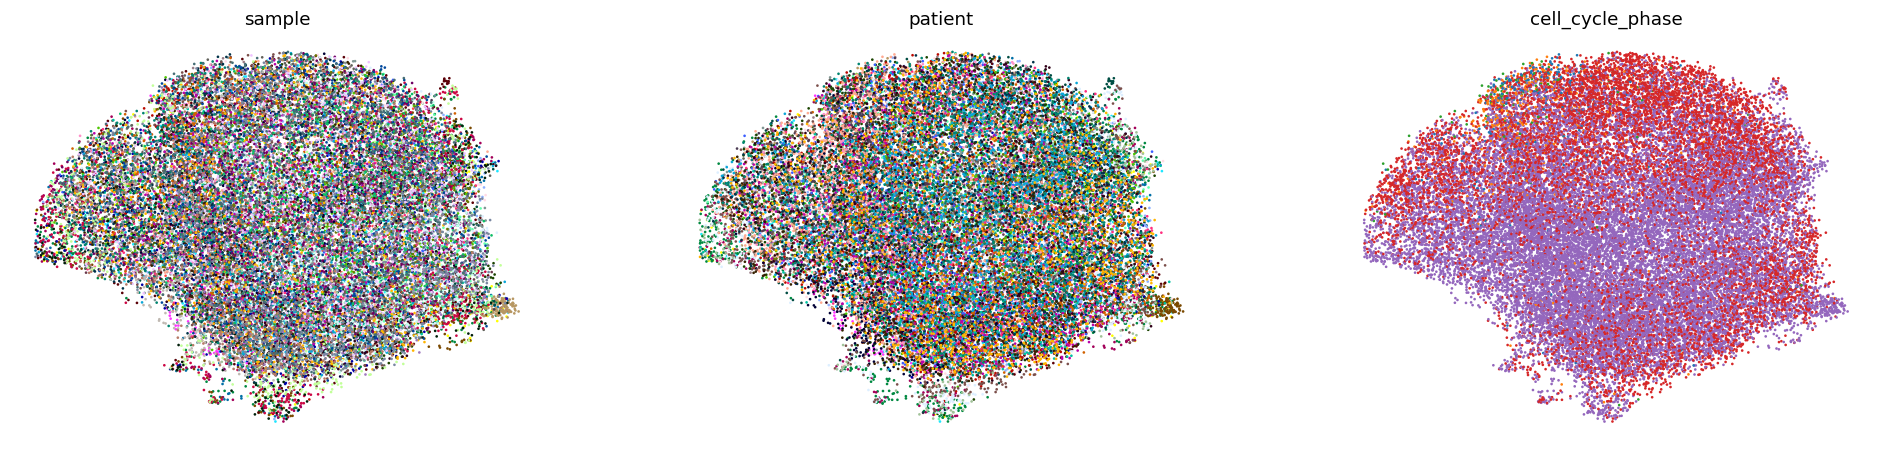

In [9]:
adata.obs['cell_cycle_phase'] = adata.obs['cell_cycle_phase'].astype(str)
c3 = ['sample', 'patient', 'cell_cycle_phase']
sc.pl.umap(adata, color=c3, size=12, frameon=False,
           ncols=3, legend_loc=None, show=True)
print('Gate 1: samples/patients intermix per-neighbourhood (iLISI %.1f of %d) on one '
      'continuous connected manifold -> GO' % (sweep[10], nsamp))

### Save processed data

In [10]:
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum()>0 and conv.notna().sum()>=0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (33067, 31585)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)`, `size=30`) on the house orientation so this panel shares one
consistent layout with the 02/03/04 UMAPs. Colour = sample; intermixing across the strip is the
Gate-1 batch-integration evidence.

saved samples.pdf | cells: 33067 | samples: 54


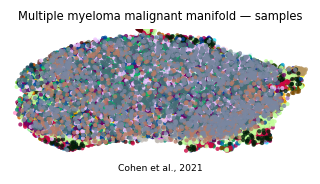

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.get_legend().remove() if ax.get_legend() else None
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Multiple myeloma malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Cohen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0], '| samples:', plot.obs['sample'].nunique())